# Fitting your own measurement

*Tsviki Y. Hirsh, 25 October 2026*

Measured counts are read as in `nbragg.Data.from_counts`: the sample counts of
one period (summed over all periods) and the open beam measured with one short
pulse per period. Here we first write such files from a simulation.

In [1]:
import numpy as np
import pandas as pd
import nbragg
import frame_overlap as fo

xs = nbragg.CrossSection(iron="Fe_sg229_Iron-alpha.ncmat")
pattern = fo.Pattern([0, 11.97e-3, 22.33e-3, 35.48e-3])
truth = fo.TransmissionModel(xs, pattern=pattern, vary_basic=True, vary_strain=True, strain=5e-4)
truth.params["thickness"].set(value=1.8)
sim = truth.simulate(time=8 * 3600, flux=5e6, area=0.72, efficiency=0.045, seed=7)
sim.to_csv("my_sample_counts.csv")                                       # tof, counts, err
open_counts = sim.openbeam.rate * 200e-6 * (16 * 3600) * 20              # one 200 us pulse per period, 16 h
pd.DataFrame(dict(tof=np.arange(len(open_counts)), counts=np.random.default_rng(8).poisson(open_counts))
             ).to_csv("my_open_beam_one_pulse.csv", index=False)

Read the files, with the pulse pattern, the measurement times, the flight path
and the time bin:

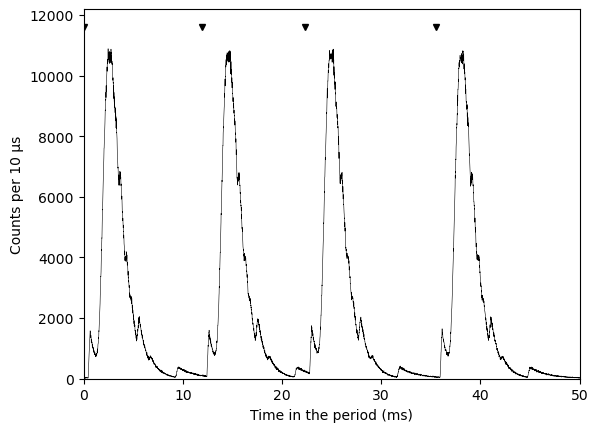

In [2]:
data = fo.Data.from_counts("my_sample_counts.csv", "my_open_beam_one_pulse.csv", pattern=pattern,
                           time=8 * 3600, openbeam_time=16 * 3600, L=9.0, tstep=10e-6)
data.plot();

[[Rietveld fit]]
    converged after 16 evaluations
    deviance per bin = 1.041 (5000 bins)
[[Variables]]
    thickness         1.79948 +/- 0.000382
    strain        0.000467167 +/- 8.38e-05  = 467.2 +/- 83.8 microstrain


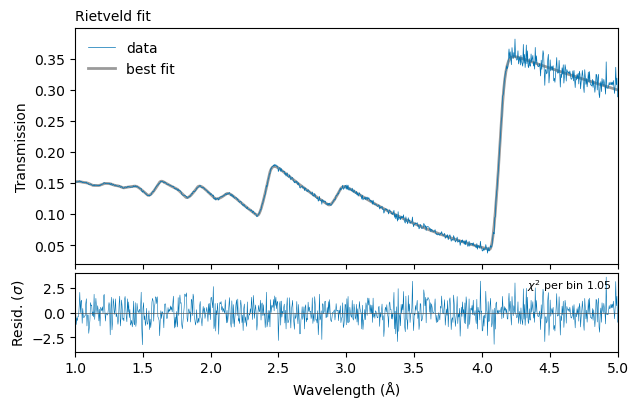

In [3]:
model = fo.TransmissionModel(xs, pattern=pattern, vary_basic=True, vary_strain=True)
result = model.fit(data)
print(result.fit_report())
result.plot();

In [4]:
result.params["strain"]            # lmfit Parameters, as in nbragg

<Parameter 'strain', value=0.00046716703699244957 +/- 8.38e-05, bounds=[-inf:inf]>

In [5]:
result.transmission().query("1 < wavelength < 5").head()     # the recovered spectrum

,wavelength,trans,err,model
228,1.004393,0.152123,0.000769,0.151970
229,1.008789,0.151113,0.000766,0.152054
230,1.013184,0.151692,0.000763,0.152105
231,1.017580,0.151517,0.000761,0.152138
232,1.021975,0.151860,0.000758,0.152147


## What must be known

The fit takes the pulse times, their intensities, the open beam and the
moderator response as known. A delay of one pulse by 1 µs, to first order, in
units of the standard deviation:

In [6]:
late = fo.Pattern(np.array(pattern.starts) + np.r_[0, 1e-6, 0, 0])
model.pattern_bias(late, flux=5e6, area=0.72, efficiency=0.045)

{'thickness': -0.2882911742842839, 'strain': 0.3829800038786994}

A common time offset, a constant background and the relative pulse
intensities can be fitted as well, at a cost in precision:

In [7]:
model.fit(data, fit_t0=True, fit_intensities=True).to_dataframe()

,parameter,value,error,value_microstrain,error_microstrain
0,thickness,1.799114e+00,6.383066e-04,NaN,NaN
1,strain,5.109729e-04,9.666614e-05,510.972894,96.666141
2,t0,-3.098080e-07,3.320966e-07,NaN,NaN
3,intensity_2,9.996143e-01,8.682793e-04,NaN,NaN
4,intensity_3,9.995583e-01,8.636394e-04,NaN,NaN
5,intensity_4,9.998776e-01,8.638905e-04,NaN,NaN
